# Parsing

In [ ]:
pip install scapy

In [ ]:
import os

#list EVERY dataset folder path needed to pull capture files from
#if everything is in 1 dataset, just list that 1 path

#COPY YOUR PATH INTO THE LIST AS SHOWN IN EXAMPLE
dataset_paths = [
#    "/datasets/pcaps-data/VPN-PCAPS-01",
#    "/datasets/pcaps-data/VPN-PCAPs-02",

]


capture_files = []

for dataset_path in dataset_paths:
    for root, dirs, files in os.walk(dataset_path):
        for f in files:
            if f.endswith(".pcap") or f.endswith(".pcapng"):
                capture_files.append(os.path.join(root, f))

print(f"\ntotal capture files found: {len(capture_files)}")

In [ ]:
#check for duplicate files
from collections import Counter

filenames_only = [os.path.basename(f) for f in capture_files]
name_counts = Counter(filenames_only)

duplicates = {name: count for name, count in name_counts.items() if count > 1}
print(f"duplicate filenames found: {len(duplicates)}")
if duplicates:
    print(duplicates)

In [ ]:
#functions to get the label and stream id from a filename
#and the PCAP parsing function
import re
from scapy.all import PcapReader, IP, TCP, UDP

def get_stream_id(filename):
    name = filename.replace(".pcapng", "").replace(".pcap", "") #pcapng first if not it wont be replaced correctly
    match = re.match(r"^(.*)([a-zA-Z])$", name)
    if match and re.search(r"\d[a-zA-Z]$", name):
        stream_id = match.group(1)
        part = match.group(2)
    else:
        stream_id = name
        part = None
    return stream_id, part

#reads filename and assigns network and category
def get_label(filename, network_type):
    name = filename.lower()

    #activity type
    #video here means LIVE video
    #streaming means the regular non live video
    categories = {
        "chat": ["chat"],
        "email": ["email", "gmail", "mail", "thunderbird", "imap", "pop"],
        "audio": ["audio", "voip", "voipbuster", "voice"],
        "video": ["video"], 
        "file_transfer": ["ftp", "ftps", "sftp", "scp", "skype_file", "skypefile", "filetransfer", "skype_transfer"],
        "p2p": ["torrent", "bittorrent", "p2p"],
        "streaming": ["spotify", "youtube", "netflix", "vimeo"],
        "browsing": ["browsing", "facebook", "google", "twitter", "ssl"]
    }

    category = "unknown"
    for cat, keywords in categories.items():
        if any(k in name for k in keywords):
            category = cat
            break

    return network_type, category
    
#PCAP parsing function
def parse_pcap_to_flows(filepath):
    flows = {}
    with PcapReader(filepath) as pcap_reader:
        for pkt in pcap_reader:
            if IP not in pkt:
                continue
            if TCP in pkt:
                proto = "TCP"
                sport = pkt[TCP].sport
                dport = pkt[TCP].dport
            elif UDP in pkt:
                proto = "UDP"
                sport = pkt[UDP].sport
                dport = pkt[UDP].dport
            else:
                continue

            src_ip = pkt[IP].src
            dst_ip = pkt[IP].dst

            if (src_ip, sport) < (dst_ip, dport):
                flow_key = (src_ip, sport, dst_ip, dport, proto)
                direction = 1
            else:
                flow_key = (dst_ip, dport, src_ip, sport, proto)
                direction = -1

            pkt_size = len(pkt)
            pkt_time = float(pkt.time)

            if flow_key not in flows:
                flows[flow_key] = []
            flows[flow_key].append((pkt_time, pkt_size, direction))

    return flows

In [ ]:
import os
import gc
import pickle

os.makedirs("parsed_flows", exist_ok=True)

#CHECK B4 RUNNING
NETWORK_TYPE = "" 

processed_count = 0
skipped_count = 0
failed_count = 0

for filepath in capture_files:
    filename = os.path.basename(filepath)
    safe_name = filename.replace(".", "_")
    out_path = f"parsed_flows/{safe_name}.pkl"

    if os.path.exists(out_path):
        skipped_count += 1
        continue

    stream_id, part = get_stream_id(filename)
    network_type, category = get_label(filename, network_type=NETWORK_TYPE)

    try:
        file_flows = parse_pcap_to_flows(filepath)
    except Exception as e:
        print(f"failed on {filename}: {e}")
        failed_count += 1
        continue

    file_records = []
    for flow_key, packet_seq in file_flows.items():
        file_records.append({
            "filepath": filepath,
            "filename": filename,
            "stream_id": stream_id,
            "part": part,
            "network_type": network_type,
            "category": category,
            "flow_key": flow_key,
            "packet_seq": packet_seq
        })

    with open(out_path, "wb") as f:
        pickle.dump(file_records, f)

    print(f"done: {filename} -> {len(file_records)} flows")
    processed_count += 1

    del file_flows, file_records
    gc.collect()

print(f"\nbatch complete: {NETWORK_TYPE}")
print(f"newly processed: {processed_count}")
print(f"skipped (already done): {skipped_count}")
print(f"failed: {failed_count}")
print(f"total files in capture_files: {len(capture_files)}")

In [ ]:
#see which files labelled as unknown
unknown_files = df[df["category"] == "unknown"]["filename"].unique()
print(unknown_files)

In [ ]:
import glob
import pandas as pd

#only combine the pickles belonging to files from THIS batch's capture_files
#matches by filename, so it only picks up what was just parsed in this run
batch_filenames = set(os.path.basename(f) for f in capture_files)

batch_records = []
for pkl_path in glob.glob("parsed_flows/*.pkl"):
    with open(pkl_path, "rb") as f:
        file_records = pickle.load(f)
        if file_records and file_records[0]["filename"] in batch_filenames:
            batch_records.extend(file_records)

df = pd.DataFrame(batch_records)
print(f"total flows in this batch ({NETWORK_TYPE}): {len(df)}")
print(df["category"].value_counts())

#save this batch's dataframe with a name based on its network type
df.to_pickle(f"nonvpn2_files_AL2.pkl")

In [ ]:
first_row = df.iloc[0]
for col in df.columns:
    if col == "packet_seq":
        print(f"{col}: {first_row[col][:5]} ... ({len(first_row[col])} total packets)")
    else:
        print(f"{col}: {first_row[col]}")

# Loading parsed files in

In [1]:
import pandas as pd

#load every saved batch back in
#load YOUR own .pkl files as shown in the example
non_vpn1 = pd.read_pickle("/example/nonvpn1_files_AL2.pkl")
non_vpn2 = pd.read_pickle("/example/nonvpn2_files_AL2.pkl")
non_vpn3 = pd.read_pickle("")
vpn = pd.read_pickle("")
tor = pd.read_pickle("")

#combine into one dataframe
df_combined = pd.concat([non_vpn1, non_vpn2, non_vpn3, vpn, tor], ignore_index=True)

print(f"total combined flows: {len(df_combined)}")

#save the final combined dataset
#you can save it in 1 file if you wish
#df_combined.to_pickle("combined_flows.pkl")

print(f"shape: {df_combined.shape}")

df_combined.head(5)

total combined flows: 188670
shape: (188670, 8)


,filepath,filename,stream_id,part,network_type,category,flow_key,packet_seq
0,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.93, 57806, 255.255.255.255, 10505...","[(1432572763.37583, 127, 1)]"
1,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.183, 63970, 255.255.255.255, 1900...","[(1432572763.491782, 215, 1), (1432572763.4919..."
2,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.117, 54995, 255.255.255.255, 1050...","[(1432572763.515294, 131, 1)]"
3,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.217, 5353, 224.0.0.251, 5353, UDP)","[(1432572763.944989, 86, 1), (1432572772.96247..."
4,/kaggle/input/datasets/trayne/pcaps-data/NonVP...,email1a.pcap,email1,a,non_vpn,email,"(131.202.240.183, 54357, 131.202.243.255, 3241...","[(1432572764.072761, 63, 1), (1432572769.07285..."


In [2]:
first_row = df_combined.iloc[0]
for col in df_combined.columns:
    if col == "packet_seq":
        print(f"{col}: {first_row[col][:5]} ... ({len(first_row[col])} total packets)")
    else:
        print(f"{col}: {first_row[col]}")

filepath: /kaggle/input/datasets/trayne/pcaps-data/NonVPN-PCAPs-01/email1a.pcap
filename: email1a.pcap
stream_id: email1
part: a
network_type: non_vpn
category: email
flow_key: ('131.202.240.93', 57806, '255.255.255.255', 10505, 'UDP')
packet_seq: [(1432572763.37583, 127, 1)] ... (1 total packets)


# Cleaning

In [3]:
def get_flow_duration(packet_seq):
    if len(packet_seq) < 2: #need 2 packets to find difference
        return 0 
    timestamps = [p[0] for p in packet_seq]
    return max(timestamps) - min(timestamps)

#duration of flow
df_combined["flow_duration"] = df_combined["packet_seq"].apply(get_flow_duration)

print("description")
print(df_combined["flow_duration"].describe())
print()
print("quantile")
print(df_combined["flow_duration"].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0]))
print()
print("bins")
print(df_combined["flow_duration"].value_counts(bins=20).sort_index())

description
count    188670.000000
mean        252.848853
std         798.185257
min           0.000000
25%           0.144604
50%           0.412059
75%           0.421085
max        6413.501714
Name: flow_duration, dtype: float64

quantile
0.50       0.412059
0.75       0.421085
0.90     746.812158
0.95    2126.450915
0.99    4076.028234
1.00    6413.501714
Name: flow_duration, dtype: float64

bins
(-6.415, 320.675]       165223
(320.675, 641.35]         3538
(641.35, 962.025]         2894
(962.025, 1282.7]         2286
(1282.7, 1603.375]        2189
(1603.375, 1924.051]      2014
(1924.051, 2244.726]      1701
(2244.726, 2565.401]      1666
(2565.401, 2886.076]      1397
(2886.076, 3206.751]      1228
(3206.751, 3527.426]      1117
(3527.426, 3848.101]       956
(3848.101, 4168.776]       751
(4168.776, 4489.451]       570
(4489.451, 4810.126]       435
(4810.126, 5130.801]       350
(5130.801, 5451.476]       194
(5451.476, 5772.152]        79
(5772.152, 6092.827]        78
(6092.8

In [4]:
#number of packets in each flow
df_combined["packet_count"] = df_combined["packet_seq"].apply(len)

print("description")
print(df_combined["packet_count"].describe())
print()
print("quantile")
print(df_combined["packet_count"].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0]))
print()
print("bins")
print(df_combined["packet_count"].value_counts(bins=20).sort_index())

description
count    1.886700e+05
mean     2.182734e+02
std      1.346167e+04
min      1.000000e+00
25%      2.000000e+00
50%      2.000000e+00
75%      2.000000e+00
max      2.951457e+06
Name: packet_count, dtype: float64

quantile
0.50          2.0
0.75          2.0
0.90          4.0
0.95          6.0
0.99         71.0
1.00    2951457.0
Name: packet_count, dtype: float64

bins
(-2950.4570000000003, 147573.8]    188615
(147573.8, 295146.6]                   18
(295146.6, 442719.4]                   15
(442719.4, 590292.2]                    8
(590292.2, 737865.0]                    3
(737865.0, 885437.8]                    2
(885437.8, 1033010.6]                   2
(1033010.6, 1180583.4]                  0
(1180583.4, 1328156.2]                  0
(1328156.2, 1475729.0]                  5
(1475729.0, 1623301.8]                  0
(1623301.8, 1770874.6]                  0
(1770874.6, 1918447.4]                  0
(1918447.4, 2066020.2]                  0
(2066020.2, 2213593.0]        

In [5]:
#from above, most packets fall into first bin.
#find the number of flows that contain each packet, up to 20
print(df_combined["packet_count"].value_counts().sort_index().head(20))

packet_count
1      20923
2     133819
3        650
4      19807
5        234
6       4165
7        454
8        852
9        249
10       569
11       249
12       299
13       297
14       214
15       287
16       163
17       189
18       181
19       202
20       171
Name: count, dtype: int64


In [6]:
#see how the duration is like for packet_count >=5
df_packet_filtered = df_combined[df_combined["packet_count"] >= 5]
print(df_packet_filtered["flow_duration"].describe())
print()
print(df_packet_filtered["flow_duration"].quantile([0.05, 0.1, 0.25, 0.5]))

count    13471.000000
mean      1111.686472
std       1526.169041
min          0.000846
25%          8.394011
50%        220.760416
75%       2037.051153
max       6413.501714
Name: flow_duration, dtype: float64

0.05      0.159927
0.10      0.485169
0.25      8.394011
0.50    220.760416
Name: flow_duration, dtype: float64


In [10]:
#the packet_count filter removed a lot of the flows with very low duration
#so dont need to filter noise from duration
MIN_PACKETS = 5 #spike at packet 2 and 4. so set min=5 to remove those noise
MIN_DURATION = 1.0 #set this to 1. duration < 1 has no meaningful temporal data

df_clean = df_combined[(df_combined["packet_count"] >= MIN_PACKETS) & (df_combined["flow_duration"] >= MIN_DURATION)].copy()

print(f"before: {len(df_combined)}, after: {len(df_clean)}")
print()
print(df_clean["flow_duration"].describe())
print()
print(df_clean["flow_duration"].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0]))

before: 188670, after: 11885



count    11885.000000
mean      1260.000541
std       1566.265065
min          1.000637
25%         33.422062
50%        381.199485
75%       2343.469820
max       6413.501714
Name: flow_duration, dtype: float64

0.50     381.199485
0.75    2343.469820
0.90    3814.513671
0.95    4471.033657
0.99    5521.663819
1.00    6413.501714
Name: flow_duration, dtype: float64

# EDA

In [21]:
#duration by category and network
print("=== duration by category ===")
display(df_clean.groupby("category")["flow_duration"].describe())

print("\n=== duration by network_type ===")
display(df_clean.groupby("network_type")["flow_duration"].describe())


#results:
#CATEGORY
#audio dominates, as expected
#chat, email, video, p2p, streaming on shorter side
#browsing, email, file_transfer, p2p, video have much larger avg than median: few extreme outliers to pull them up

#NETWORK
#non_vpn longest, followed by tor and vpn

=== duration by category ===


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
audio,5403.0,2149.549269,1707.408962,1.009895,318.289979,2100.363737,3509.352972,6375.836560
browsing,31.0,1077.745105,1351.671791,1.218211,189.011474,302.327444,1700.318048,4902.175732
chat,781.0,381.428095,355.036338,1.024936,59.274782,240.235541,690.690448,1336.179729
email,594.0,372.859022,866.920590,1.007133,2.518546,6.364699,501.741219,5619.325462
file_transfer,2767.0,871.295257,1186.543701,1.032077,6.108362,116.423438,1612.493256,5002.507509
p2p,426.0,90.828261,532.066458,1.070224,2.425793,7.085809,20.179125,6413.501714
streaming,1417.0,170.618714,381.543803,1.000637,17.843951,83.807249,210.852744,6375.836560
video,466.0,251.018222,422.152350,1.014952,11.670427,65.333111,283.712605,3703.812379



=== duration by network_type ===


,count,mean,std,min,25%,50%,75%,max
network_type,,,,,,,,
non_vpn,9568.0,1464.748873,1619.862151,1.005867,60.820939,669.008383,2638.406671,5886.010418
tor,326.0,513.490014,1124.441308,1.000637,2.315480,90.137115,404.691567,6413.501714
vpn,1991.0,398.288027,890.538931,1.009895,8.959246,59.190987,214.875712,4116.135039


In [17]:
#bytes by category
#sanity check: streaming/video/file transfer should be larger than chat/email
def get_total_bytes(packet_seq):
    return sum(p[1] for p in packet_seq)

df_clean["total_bytes"] = df_clean["packet_seq"].apply(get_total_bytes)

display(df_clean.groupby("category")["total_bytes"].describe())

#results
#browsing, file_transfer, streaming have very large skews
#investigated them, SEEMS genuine skew rather than mistake

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
audio,5403.0,3.470441e+05,4.932894e+06,260.0,384.00,452.0,2492.00,1.313403e+08
browsing,31.0,1.749849e+07,3.585700e+07,594.0,11483.00,626238.0,15899292.50,1.328807e+08
chat,781.0,8.286054e+04,3.756707e+05,240.0,1792.00,4692.0,10040.00,3.922199e+06
email,594.0,5.742318e+05,6.880396e+06,315.0,3119.25,4469.0,5241.25,1.096181e+08
file_transfer,2767.0,7.850504e+06,9.046630e+07,294.0,384.00,660.0,5545.00,2.430622e+09
p2p,426.0,1.268841e+07,1.192707e+08,270.0,6896.00,644095.5,1388242.75,1.296150e+09
streaming,1417.0,2.510632e+06,2.581639e+07,282.0,660.00,1615.0,8479.00,7.850586e+08
video,466.0,1.201392e+07,8.105671e+07,300.0,1250.00,3413.5,11958.75,1.191458e+09


In [13]:
#sanity check: 1 stream_id : 1 category
#return empty list if everything is correct

inconsistent = df_clean.groupby("stream_id")["category"].nunique()
print(inconsistent[inconsistent > 1])

Series([], Name: category, dtype: int64)


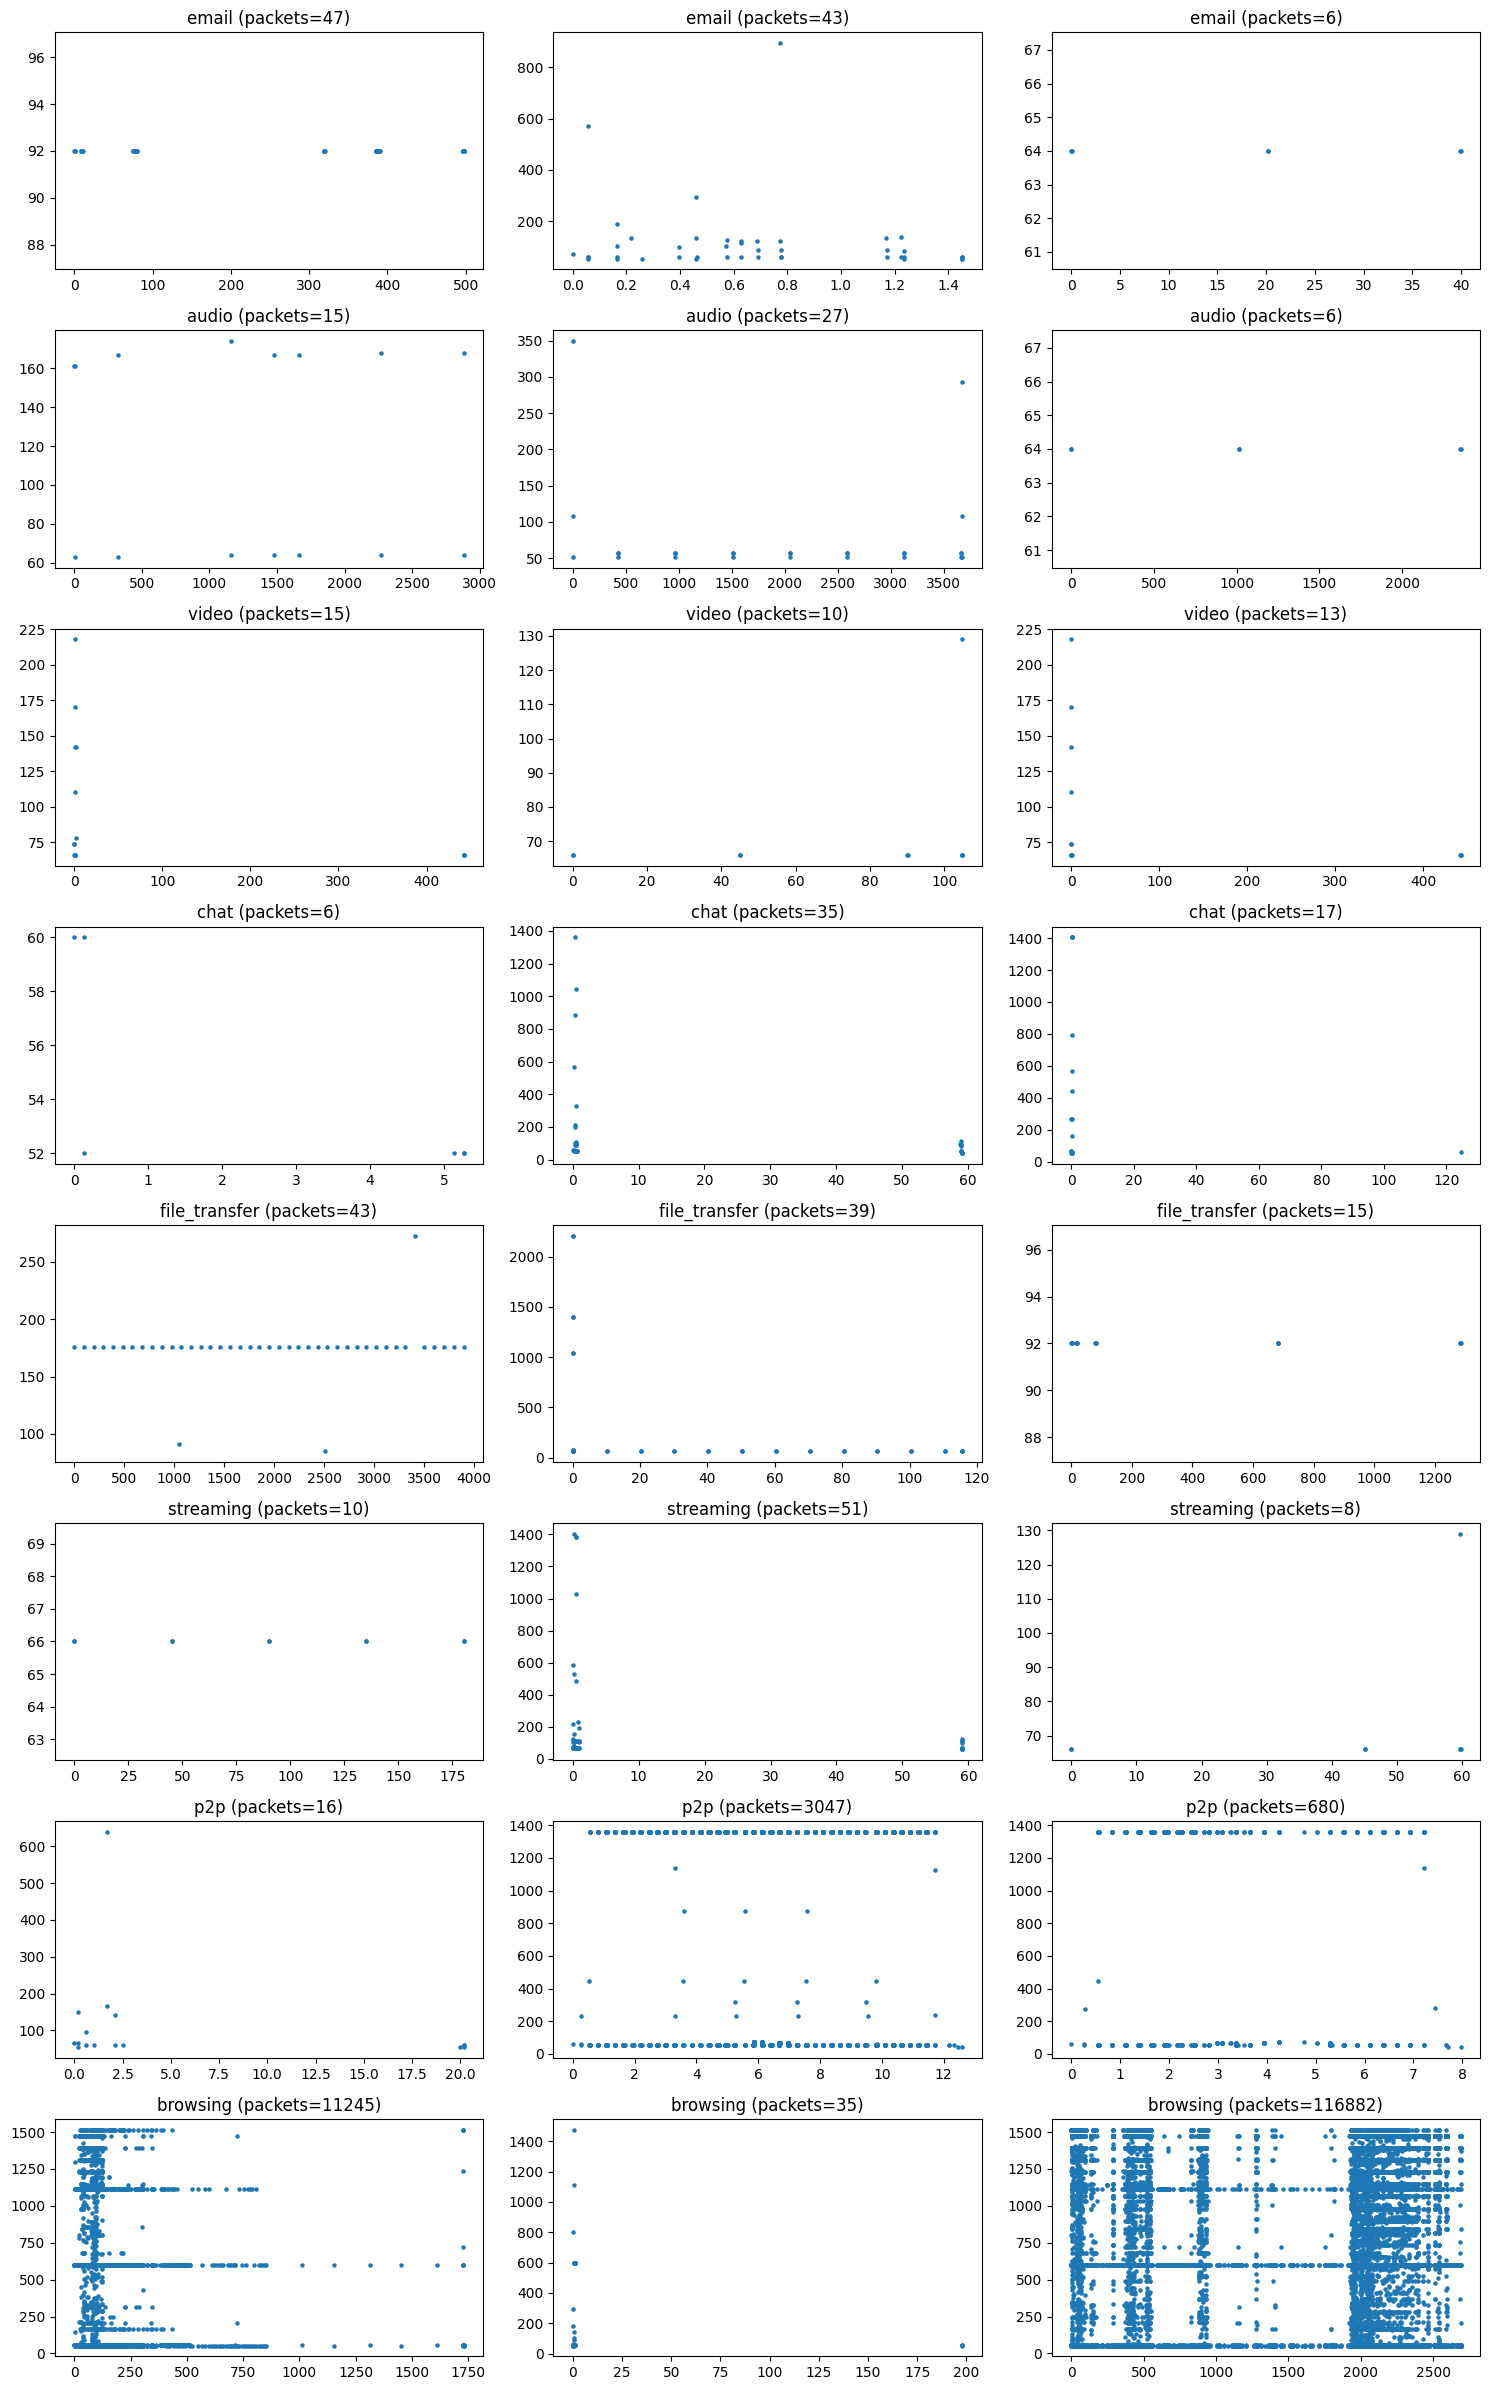

In [27]:
#randomly sample 3 flows per category to see how different they are
#can give idea of how distinguishable the embeddings are
import matplotlib.pyplot as plt

categories = df_clean["category"].unique()
n_examples = 3

fig, axes = plt.subplots(len(categories), n_examples, figsize=(15, 3*len(categories)))

for row_idx, cat in enumerate(categories):
    samples = df_clean[df_clean["category"] == cat].sample(min(n_examples, len(df_clean[df_clean["category"] == cat])), random_state=42)
    for col_idx, (_, sample) in enumerate(samples.iterrows()):
        ax = axes[row_idx, col_idx]
        start_time = sample["packet_seq"][0][0]
        times = [p[0] - start_time for p in sample["packet_seq"]]
        sizes = [p[1] for p in sample["packet_seq"]]
        ax.scatter(times, sizes, s=5)
        ax.set_title(f"{cat} (packets={sample['packet_count']})")

plt.tight_layout()
plt.show()

# EDA